In [1]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import seaborn as sns
import numpy as np
from scipy.interpolate import griddata
from matplotlib.patches import Patch



MODEL = "Scalar"
INPUT_PICKLE = Path('../Recast/Scalar/Scalar_smodels.pcl')


# Mass columns are the ones used in the uploaded SModelS notebooks.
MASS_COL = "mass.5000002"
DM_MASS_COL = "mass.5000012"
K_FACTOR = 1.0
R_CUT = 1.0 / K_FACTOR

SHOW_TOTAL_EXCLUSION = True
FILL_EXCLUDED_REGIONS = True
FILL_LEFT_MASS = 200.0     # Exactly as in plotExclusion-DirectSearches
FILL_ALPHA = 0.18          # Exactly as in plotExclusion-DirectSearches
BENCHMARK = (1500.0, 100.0)
SHOW_BENCHMARK = True
X_LIM = (300.0, 1750.0)
Y_LIM = (40.0, 500.0)
LEGEND_FONTSIZE = 15
INTERPOLATION_RESOLUTION = 200  # auxPlots original grid used to FIND the r=1 contours

# The PCHIP smoothing you used for Zprime, adapted to M_limit(deltaM).
SMOOTH_SIGMA = 1.2          # Gaussian width IN OUTPUT GRID POINTS; 0 disables smoothing
PCHIP_KNOT_SPACING = 2.0    # GeV in deltaM, knot spacing before dense PCHIP reconstruction
BOUNDARY_NPTS = 650         # dense common deltaM grid, including both Y_LIM endpoints
FILL_GAP_TOLERANCE_Y = 3.0   # GeV; only tiny gaps between supported contours
FILL_GAP_TOLERANCE_X = 20.0  # GeV; require neighboring masses to be close
# 'individual': transparent fills for each analysis, 'total': one neutral combined fill, 'none': no fill.
FILL_STYLE = 'individual'  # Colored analysis fills; 'total' for neutral, 'none' for contours only
# Optional targeted repair of *short internal* gaps only, based on the two contour
# endpoints. This does NOT extrapolate above or below the analysis contour's support.
# Set to {} to retain all raw discontinuities. Repairs are visualization-only.
ANALYSIS_GAP_REPAIR = {
    'CMS-SUS-19-010': {'max_delta_y': 32.0, 'max_delta_m': 85.0}
}
SHOW_REPAIR_DIAGNOSTICS = True
# Raw combined-all contour is saved but NOT used for the black line (it is interpolated independently).

# Distinct lines with matching translucent colors.
PALETTE = [
    "#0072B2",  # Blue
    "#E41A1C",  # Red
    "#009E73",  # Green
    "#984EA3",  # Purple
    "#F781BF",  # Pink
    "#00A6A6",  # Teal
    "#4D4D4D",  # Dark gray
]

pd.option_context('display.max_columns', -1)

pd.options.mode.chained_assignment = None #Disable copy warnings
# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)




## Load Results

In [2]:
if not INPUT_PICKLE.exists():
    raise FileNotFoundError(f"Run ../Recast/getSModelSData.ipynb first to generate {INPUT_PICKLE}.")
dataDF = pd.read_pickle(INPUT_PICKLE).reset_index(drop=True).copy()
for col in (MASS_COL, DM_MASS_COL):
    if col not in dataDF:
        raise KeyError(f"Mass column {col} not found. Available: {[c for c in dataDF if c.startswith('mass.')]}")
dataDF['deltaM'] = pd.to_numeric(dataDF[MASS_COL]) - pd.to_numeric(dataDF[DM_MASS_COL])

# Select only points with deltaM > 50 GeV and M > 500 GeV
dataDF = dataDF[(dataDF['deltaM'] > Y_LIM[0]) & (dataDF[MASS_COL] > X_LIM[0])].copy()



### Get list of excluded points and relevant analyses

In [3]:
excludedDF = dataDF[dataDF['ExptRes.result0.r'] > 1.0].copy()
print(f"Found {len(excludedDF)} excluded points (r>1) out of {len(dataDF)} total points.")

## Get minimal set of analyses excluding all excluded points.
excluded_analysis_ids = {}
for index, row in excludedDF.iterrows():
    for col in dataDF.columns:
        if col.startswith('ExptRes.result') and col.endswith('.r'):
            if row[col] > 1.0:
                anaID = row[col[:-2]+'.AnalysisID']
                excluded_analysis_ids.setdefault(anaID, [])
                excluded_analysis_ids[anaID].append(index)

excluded_analysis_ids_sorted = {anaID : excluded_analysis_ids[anaID] for anaID in sorted(excluded_analysis_ids.keys(), key=lambda x: len(excluded_analysis_ids[x]), reverse=True)}
excluded_analysis_ids = excluded_analysis_ids_sorted
print(f"{len(excluded_analysis_ids)} excluding analysis IDs")
for anaID,indices in sorted(excluded_analysis_ids.items(), key=lambda x: len(x), reverse=True):
    print(f"  {anaID}: {len(indices)} excluded points")

Found 297 excluded points (r>1) out of 729 total points.
23 excluding analysis IDs
  CMS-SUS-20-002: 215 excluded points
  CMS-SUS-19-006-agg: 206 excluded points
  CMS-SUS-19-010: 194 excluded points
  ATLAS-SUSY-2018-08: 186 excluded points
  CMS-SUS-19-006: 150 excluded points
  ATLAS-SUSY-2018-12: 144 excluded points
  CMS-SUS-19-009: 140 excluded points
  CMS-SUS-16-033: 135 excluded points
  CMS-SUS-16-036: 57 excluded points
  ATLAS-SUSY-2016-15: 44 excluded points
  CMS-SUS-16-051: 43 excluded points
  ATLAS-SUSY-2016-16: 35 excluded points
  CMS-SUS-19-011: 26 excluded points
  CMS-SUS-17-010: 24 excluded points
  CMS-SUS-18-004: 24 excluded points
  CMS-SUS-16-050-agg: 19 excluded points
  CMS-SUS-16-050: 18 excluded points
  CMS-PAS-SUS-16-052: 12 excluded points
  CMS-SUS-17-005: 11 excluded points
  CMS-PAS-SUS-16-052-agg: 11 excluded points
  CMS-SUS-16-009: 8 excluded points
  ATLAS-SUSY-2016-17: 8 excluded points
  ATLAS-SUSY-2015-02: 1 excluded points


## Get minimal set of analyses

In [4]:
minimal_sets = []
all_excluded_indices = set(excludedDF.index)
for size in range(len(excluded_analysis_ids) + 1):
    minimal_sets = []
    for analyses_set in combinations(excluded_analysis_ids.keys(), size):
        excluded_indices_by_set = set([])
        for anaID in analyses_set:
            excluded_indices_by_set.update(excluded_analysis_ids[anaID])
        if len(all_excluded_indices) != len(excluded_indices_by_set):
            continue
        if all_excluded_indices.issubset(excluded_indices_by_set):
            minimal_sets.append(analyses_set)
    if minimal_sets:
        break
if not minimal_sets:
    minimal_sets = [list(excluded_analysis_ids.keys())]
    
# Sort sets by total excluded points covered, descending.
minimal_sets = sorted(minimal_sets, key=lambda x: sum(len(excluded_analysis_ids[anaID]) for anaID in x), reverse=True)

for i,m_set in enumerate(minimal_sets):
    excluded_indices_by_set = set([])
    for anaID in m_set:
        excluded_indices_by_set.update(excluded_analysis_ids[anaID])
    print(f"\nMinimal set {i+1}:")
    print(f"  Excluded points: {len(excluded_indices_by_set)}")
    for anaID in m_set:
        print("  ", anaID, len(excluded_analysis_ids[anaID]), "excluded points")

# Use the first minimal set for plotting.
minimal_analyses = {anaID: excluded_analysis_ids[anaID] for anaID in minimal_sets[0]}


Minimal set 1:
  Excluded points: 297
   CMS-SUS-20-002 215 excluded points
   CMS-SUS-19-006-agg 206 excluded points
   CMS-SUS-19-010 194 excluded points


## Get dataframe for each analysis

In [5]:
anaDFDict = {}
anaColumns = np.array([col for col in dataDF.columns if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')])
rColumns = np.array([col for col in dataDF.columns if col.startswith('ExptRes.result') and col.endswith('.r')])
for anaID in minimal_analyses:
    anaDFDict[anaID] = dataDF.drop(columns=np.concatenate((anaColumns, rColumns))).copy()
    anaDFDict[anaID]['r'] = 0.0
    for irow,row in dataDF.iterrows():
        if not anaID in row[anaColumns].values:
            continue
        r_values = row[rColumns[np.where(row[anaColumns].values == anaID)]].values
        r = max(r_values)
        anaDFDict[anaID].loc[irow,'r'] = r



## Excluded scan points by analysis

In [6]:
color_by_analysis = {a: PALETTE[i % len(PALETTE)] for i, a in enumerate(minimal_analyses)}

In [7]:
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import PchipInterpolator

def smooth(x,y,sigma=1.0,npts=100):
    # Smooth in log-space on a uniform mass grid
    xg = np.linspace(x.min(), x.max(), npts)
    yg = PchipInterpolator(x, y)(xg)
    yg = gaussian_filter1d(yg, sigma=sigma, 
                           mode='nearest')
    return xg,yg

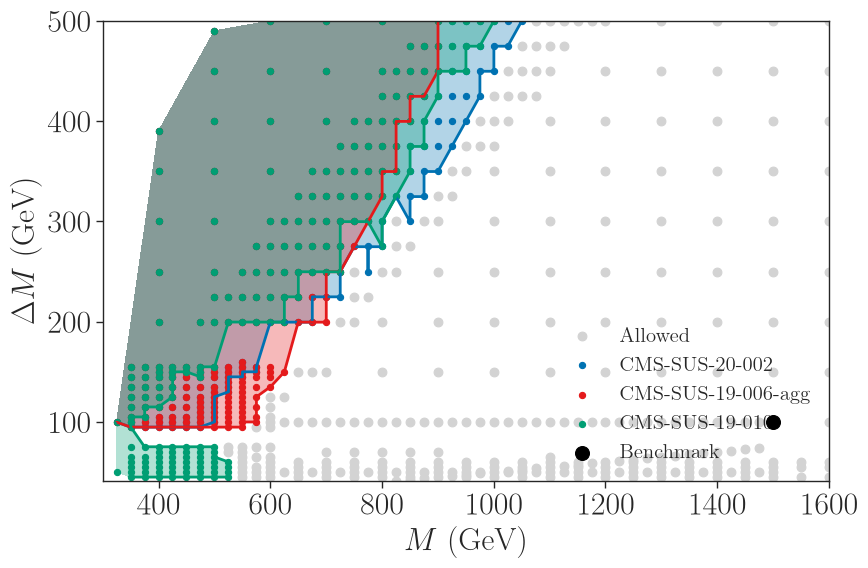

In [8]:
fig = plt.figure(figsize=(9, 6))
allowed = dataDF[~dataDF.index.isin(excludedDF.index)]
plt.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')

x = dataDF[MASS_COL].values
y = dataDF.deltaM.values
for ana,indices_excluded in minimal_analyses.items():
    anaDF = dataDF.loc[indices_excluded]
    plt.scatter(anaDF[MASS_COL], anaDF.deltaM, s=20, color=color_by_analysis[ana], label=ana)

    # z = 1 if the grid point is in the subset, 0 otherwise.
    z = np.array([1.0 if index in indices_excluded else 0.0 for index in dataDF.index])
    # Triangulate the irregular grid and draw the 0.5 boundary
    triang = tri.Triangulation(x, y)
    plt.tricontourf(triang, z, levels=[0.99, 10.1], colors=[color_by_analysis[ana]], alpha=0.3)  # filled region
    plt.tricontour(triang, z, levels=[0.99], colors=color_by_analysis[ana], linewidths=2)  


if SHOW_BENCHMARK:
    plt.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
plt.xlabel(r'$M$ (GeV)', fontsize=23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize=23)
plt.xlim(300, 1600)
plt.tick_params(axis='both', labelsize=23)
plt.legend(loc='lower right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.show()

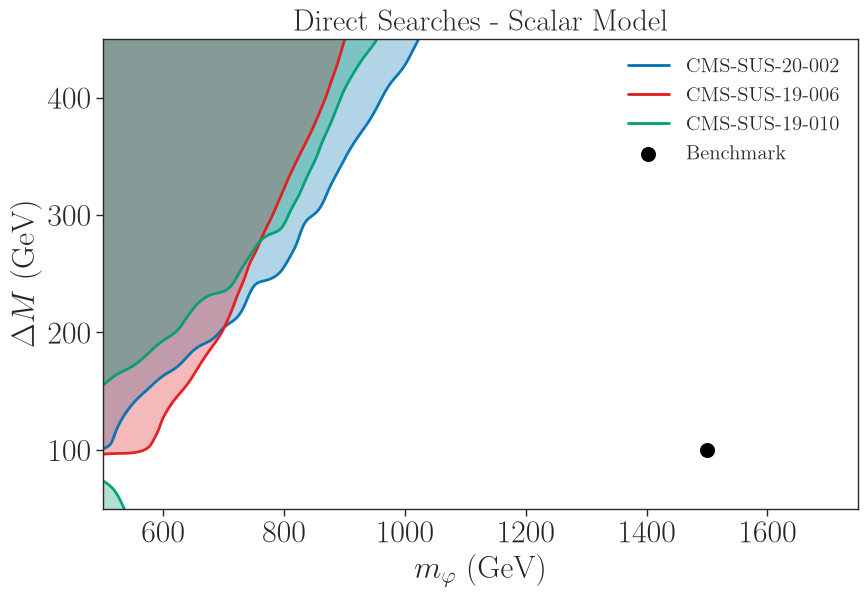

In [9]:
from scipy.ndimage import gaussian_filter
fig = plt.figure(figsize=(9, 6))
allowed = dataDF[~dataDF.index.isin(excludedDF.index)]
# plt.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')
for ana,anaDF_all in anaDFDict.items():
    label = ana.replace('-agg','')
    x = anaDF_all[MASS_COL].values.astype(float)
    y = anaDF_all.deltaM.values.astype(float)
    logr = np.log10(np.clip(anaDF_all.r.values.astype(float), 1e-3, None))
    xi = np.linspace(X_LIM[0], X_LIM[1], 1000)
    yi = np.linspace(Y_LIM[0], Y_LIM[1], 1000)
    X, Y = np.meshgrid(xi, yi)
    Z = griddata((x, y), logr, (X, Y), method='linear', 
                 fill_value=0.0)
    Z_smooth = gaussian_filter(Z, sigma=(10.0,10.0), mode='nearest')
    # z = 1 if the grid point is in the subset, 0 otherwise.                                                                                                
    plt.contourf(X, Y, Z_smooth, levels=[0.0,2.0], 
                 colors=[color_by_analysis[ana]], alpha=0.3)
    contours = plt.contour(X, Y, Z_smooth, levels=[0.0], alpha=0.95,
                           colors=[color_by_analysis[ana]], linewidths=2.0, linestyles='solid')
    # Plot non-smoothed curves as a cross check:
    # plt.contour(X, Y, Z, levels=[0.0], alpha=0.5,
                            #    colors=[color_by_analysis[ana]], linewidths=2.0, linestyles='dashed')
    plt.plot([], [], color=color_by_analysis[ana], lw=2.0, label=label)   # legend proxy


if SHOW_BENCHMARK:
    plt.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
plt.xlabel(r'$m_{\varphi}$ (GeV)', fontsize=23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize=23)
plt.xlim(500.0, X_LIM[1])
plt.ylim(50.,450.)
plt.tick_params(axis='both', labelsize=23)
plt.legend(loc='upper right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.title('Direct Searches - Scalar Model',fontsize=22)
plt.savefig('../paper_plots/directSearches_Scalar.png',dpi=300, bbox_inches='tight')
plt.show()


CMS-SUS-19-010, points inside plot range: 599
  Valid r > 0: 414
  Reported r = 0: 0
  No usable CMS result: 185
  Excluded (r > 1): 194


,mpsi,deltaM,r
0,825.0,41.2,0.115881
1,850.0,42.5,0.098124
2,550.0,45.0,0.895333
3,525.0,50.0,1.107110
4,525.0,55.0,1.041224
5,525.0,60.0,1.005098
6,500.0,65.0,1.186636
7,525.0,70.0,0.921785
8,500.0,75.0,1.000105
9,375.0,95.0,0.978193


Saved: ../paper_plots/cms_sus_19_010_r_heatmap_vlf.png


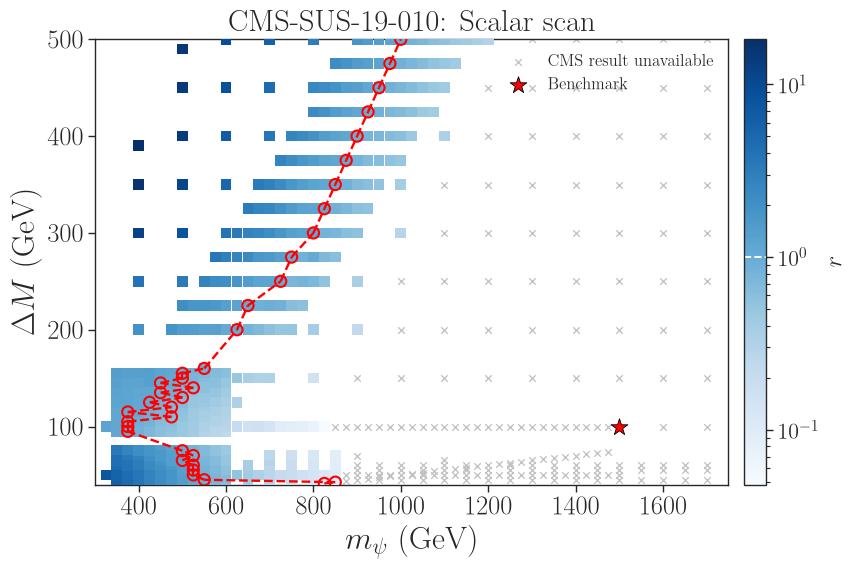

In [10]:
from matplotlib.colors import LogNorm

cms_analysis_id = 'CMS-SUS-19-010'
cms_r_column = 'r_cms_sus_19_010'

# Match each AnalysisID column with its own r column.  Do not assume
# that CMS-SUS-19-010 always appears in result0 or in minimal_analyses.
analysis_id_columns = [
    col for col in dataDF.columns
    if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')
]
matching_r_columns = []
for analysis_id_col in analysis_id_columns:
    r_col = analysis_id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF.columns:
        continue
    is_cms = dataDF[analysis_id_col].astype('string').str.strip().eq(cms_analysis_id).fillna(False)
    values = pd.to_numeric(dataDF[r_col], errors='coerce')
    matching_r_columns.append(values.where(is_cms))

if not matching_r_columns:
    raise ValueError('No paired SModelS AnalysisID/r columns found in the input data.')

# If CMS-SUS-19-010 is reported in several entries for one scan point,
# take the largest finite r. An entirely missing analysis stays NaN.
cms_r = pd.concat(matching_r_columns, axis=1).max(axis=1, skipna=True)

cms_scan = dataDF[[MASS_COL, 'deltaM']].copy()
cms_scan[cms_r_column] = cms_r
cms_scan = cms_scan.loc[
    cms_scan[MASS_COL].between(*X_LIM) & cms_scan['deltaM'].between(*Y_LIM)
].copy()

valid_positive = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].gt(0)
valid_zero = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].eq(0)
missing = ~np.isfinite(cms_scan[cms_r_column])
invalid_negative = np.isfinite(cms_scan[cms_r_column]) & cms_scan[cms_r_column].lt(0)
if invalid_negative.any():
    raise ValueError('Negative CMS-SUS-19-010 r values found; check the SModelS results.')

print(f'CMS-SUS-19-010, points inside plot range: {len(cms_scan)}')
print(f'  Valid r > 0: {valid_positive.sum()}')
print(f'  Reported r = 0: {valid_zero.sum()}')
print(f'  No usable CMS result: {missing.sum()}')
print(f'  Excluded (r > 1): {(cms_scan[cms_r_column] > 1).sum()}')

fig, ax = plt.subplots(figsize=(9, 6))

if missing.any():
    ax.scatter(cms_scan.loc[missing, MASS_COL], cms_scan.loc[missing, 'deltaM'],
               marker='x', s=22, color='0.75', linewidths=0.9,
               label='CMS result unavailable', zorder=1)
if valid_zero.any():
    ax.scatter(cms_scan.loc[valid_zero, MASS_COL], cms_scan.loc[valid_zero, 'deltaM'],
               marker='s', s=34, color='0.4', label=r'$r=0$', zorder=2)

if valid_positive.any():
    positive_scan = cms_scan.loc[valid_positive]
    r_min = min(float(positive_scan[cms_r_column].min()), 1.0)
    r_max = max(float(positive_scan[cms_r_column].max()), 1.0)
    if r_min == r_max:
        r_min, r_max = r_min / 2, r_max * 2
    image = ax.scatter(positive_scan[MASS_COL], positive_scan['deltaM'],
                       c=positive_scan[cms_r_column], cmap='Blues',
                       norm=LogNorm(vmin=r_min, vmax=r_max),
                       marker='s', s=60, edgecolors='none', rasterized=True, zorder=3)
    colorbar = fig.colorbar(image, ax=ax, pad=0.02)
    colorbar.set_label(r'$r$', fontsize=18)
    # Mark the exclusion threshold on the color scale, if in range.
    if r_min <= 1 <= r_max:
        colorbar.ax.axhline(1, color='white', lw=1.4, ls='--')
else:
    print('No positive CMS-SUS-19-010 values to color on a logarithmic scale.')

if SHOW_BENCHMARK:
    ax.scatter(BENCHMARK[0], BENCHMARK[1], c='red', marker='*',
               edgecolors='black', linewidths=0.6, s=160,
               label='Benchmark', zorder=5)

from matplotlib.lines import Line2D

# ============================================================
# Approximate r=1 boundary using closest sampled points
# ============================================================

R_TOL = 1.60       # Accept 0.7 <= r <= 1.3
MAX_DM_GAP = 60    # Maximum gap for connecting adjacent rows

approx_points = []

for dm, g in cms_scan.groupby('deltaM'):
    g = g.copy()
    g[cms_r_column] = pd.to_numeric(g[cms_r_column], errors='coerce')

    g = g[
        np.isfinite(g[cms_r_column]) &
        (g[cms_r_column] > 0)
    ]

    if g.empty:
        continue

    # Choose point closest to r=1 in logarithmic space
    idx = np.abs(np.log(g[cms_r_column])).idxmin()
    p = g.loc[idx]

    if abs(p[cms_r_column]-1) <= R_TOL:
        approx_points.append({
            'mpsi': p[MASS_COL],
            'deltaM': dm,
            'r': p[cms_r_column]
        })

approx = pd.DataFrame(
    approx_points, columns=['mpsi', 'deltaM', 'r']
).sort_values('deltaM').reset_index(drop=True)

if not approx.empty:
    # Display approximate boundary points
    display(approx)

    ax.scatter(
        approx.mpsi, approx.deltaM,
        facecolors='none', edgecolors='red',
        marker='o', s=65, linewidths=1.5, zorder=6
    )

    # Connect only adjacent rows with sufficiently small gaps
    for i in range(len(approx)-1):
        a, b = approx.iloc[i], approx.iloc[i+1]

        if b.deltaM-a.deltaM <= MAX_DM_GAP:
            ax.plot(
                [a.mpsi, b.mpsi],
                [a.deltaM, b.deltaM],
                color='red', linestyle='--',
                linewidth=1.7, zorder=5
            )

    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D(
        [0], [0], color='red', linestyle='--', lw=1.7,
        label=r'Approximate $r\simeq1$'
    ))
    ax.legend(handles=handles, fontsize=12)


ax.set_xlim(*X_LIM)
ax.set_ylim(*Y_LIM)
ax.set_xlabel(r'$m_{\psi}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\Delta M$ (GeV)', fontsize=23)
ax.set_title('CMS-SUS-19-010: Scalar scan', fontsize=22)
ax.tick_params(axis='both', labelsize=19)
if missing.any() or valid_zero.any() or SHOW_BENCHMARK:
    ax.legend(loc='upper right', framealpha=0, fontsize=12)
fig.tight_layout()

cms_plot_dir = Path('../paper_plots')
cms_plot_dir.mkdir(parents=True, exist_ok=True)
cms_plot_path = cms_plot_dir / 'cms_sus_19_010_r_heatmap_vlf.png'
#fig.savefig(cms_plot_path, dpi=300, bbox_inches='tight')
print('Saved:', cms_plot_path)
plt.show()


T2tt (CMS Fig. 8a): 110 published observed points, DeltaM = 93.15--1311.40 GeV
T2ttC (CMS Fig. 9a): 18 published observed points, DeltaM = 10.00--80.00 GeV
SModelS: 729 distinct scanned masses; 414 with r > 0


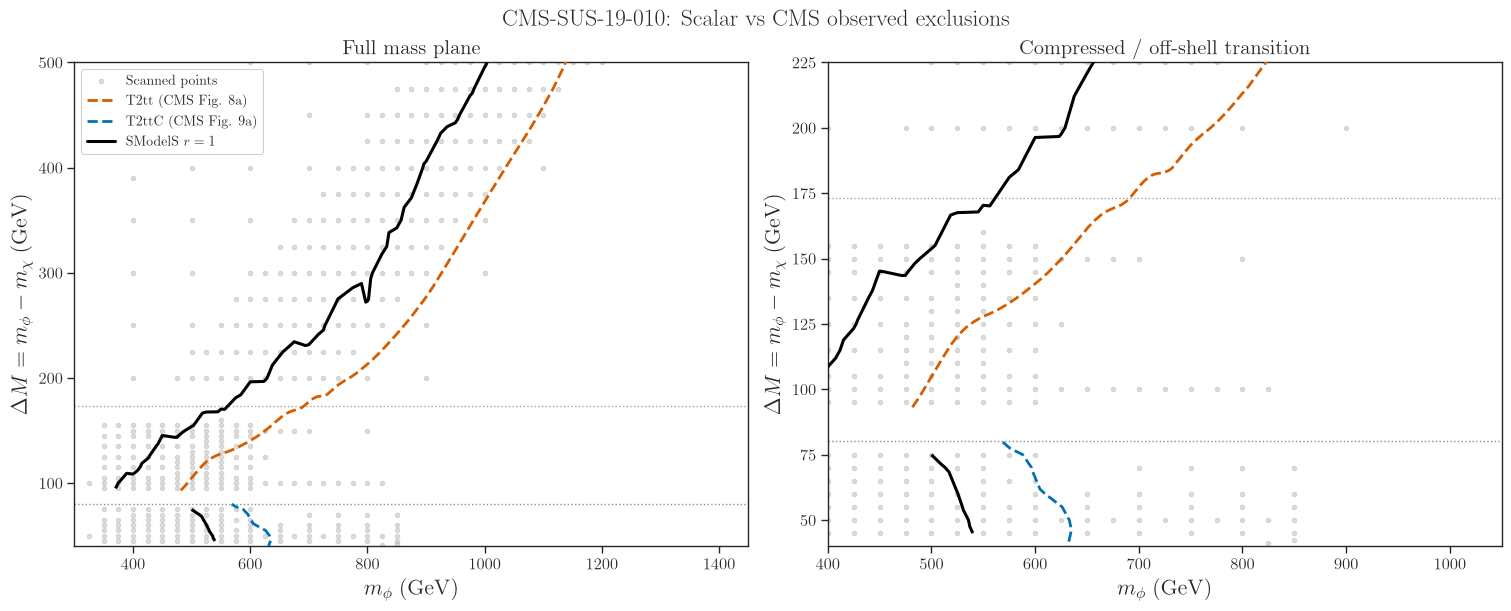

Mass differences are descriptive, NOT a validation of the same theory cross section.


,topology,deltaM,CMS_mass_GeV,SModelS_mass_GeV,difference_GeV
0,T2ttC (CMS Fig. 9a),45.0,634.32,539.84,-94.48
1,T2ttC (CMS Fig. 9a),50.0,633.01,535.72,-97.29
2,T2ttC (CMS Fig. 9a),55.0,626.08,529.85,-96.23
3,T2ttC (CMS Fig. 9a),60.0,609.70,525.62,-84.08
4,T2ttC (CMS Fig. 9a),65.0,601.38,520.65,-80.73
5,T2ttC (CMS Fig. 9a),70.0,596.67,513.45,-83.22
6,T2ttC (CMS Fig. 9a),75.0,588.10,500.01,-88.09
7,T2tt (CMS Fig. 8a),95.0,484.83,370.16,-114.66
8,T2tt (CMS Fig. 8a),100.0,492.81,374.84,-117.97
9,T2tt (CMS Fig. 8a),105.0,500.26,382.61,-117.65



Mean absolute mass difference (GeV) by CMS topology:


,count,mean,max
topology,,,
T2tt (CMS Fig. 8a),20,130.11,166.36
T2ttC (CMS Fig. 9a),7,89.16,97.29


In [14]:
# ============================================================
# CMS-SUS-19-010: SModelS Scalar r=1 vs published CMS contours
# Inputs: dataDF + the two uploaded HEPData Observed_Lines YAMLs.
# CMS Fig. 08(a): axes (m_stop, m_neutralino) -> convert to DeltaM.
# CMS Fig. 09(a): axes (m_stop, DeltaM), no conversion needed.
# These are OBSERVED exclusion contours, not cross-section UL grids.
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import yaml

ANALYSIS_ID = 'CMS-SUS-19-010'
PARENT_COL = MASS_COL            # Scalar notebook: mass.5000002
INVISIBLE_COL = DM_MASS_COL      # Scalar notebook: mass.5000012
MAX_MASS_GAP = 150.0            # Restrict triangulation to nearby scan points
MAX_DM_GAP = 60.0
MASK_TOPOLOGY_GAP = True         # Do not draw across the 80--93 GeV map gap
SHOW_SCAN_POINTS = True
SAVE_COMPARISON = True

FILES = {
    'T2tt (CMS Fig. 8a)': 'HEPData-ins1849522-v1-Figure_08-a_Observed_Lines.yaml',
    'T2ttC (CMS Fig. 9a)': 'HEPData-ins1849522-v1-Figure_09-a_Observed_Lines.yaml',
}
COLORS = {'T2tt (CMS Fig. 8a)': '#D55E00',
          'T2ttC (CMS Fig. 9a)': '#0072B2'}

def find_yaml(filename):
    # Works locally when YAMLs are placed next to the notebook,
    # and in this ChatGPT environment where uploads are mounted in /mnt/data.
    for directory in [Path.cwd(), Path.cwd().parent, Path('/mnt/data')]:
        candidate = directory / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'{filename}: place this YAML next to the notebook.')

def read_cms_observed(filename, *, figure08=False):
    with find_yaml(filename).open(encoding='utf-8') as f:
        doc = yaml.safe_load(f)
    x_entry = doc['independent_variables'][0]
    assert x_entry['header'].get('units') == 'GeV', 'Unexpected CMS mass units'
    dep = next(d for d in doc['dependent_variables']
               if 'Observed Exclusion Contour' in d['header']['name'])
    x = pd.to_numeric([v['value'] for v in x_entry['values']], errors='coerce')
    y = pd.to_numeric([v['value'] for v in dep['values']], errors='coerce')
    good = np.isfinite(x) & np.isfinite(y)
    m = np.asarray(x[good], dtype=float)
    z = np.asarray(y[good], dtype=float)
    dm = m - z if figure08 else z
    return pd.DataFrame({'mass': m, 'deltaM': dm})  # preserve HEPData line order

cms_lines = {
    label: read_cms_observed(file, figure08=('T2tt (' in label))
    for label, file in FILES.items()
}
for name, frame in cms_lines.items():
    print(f'{name}: {len(frame)} published observed points, '
          f'DeltaM = {frame.deltaM.min():.2f}--{frame.deltaM.max():.2f} GeV')

# Extract each r from its matching SModelS AnalysisID/r pair.
matched_r = []
for id_col in [c for c in dataDF if c.startswith('ExptRes.result') and c.endswith('.AnalysisID')]:
    r_col = id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF:
        continue
    mask = dataDF[id_col].astype('string').str.strip().eq(ANALYSIS_ID).fillna(False)
    matched_r.append(pd.to_numeric(dataDF[r_col], errors='coerce').where(mask))
if not matched_r:
    raise ValueError('No paired SModelS AnalysisID/r columns found')

scan_cms = dataDF[[PARENT_COL, INVISIBLE_COL]].copy()
scan_cms.columns = ['mass', 'mchi']
scan_cms['r'] = pd.concat(matched_r, axis=1).max(axis=1, skipna=True)
scan_cms[['mass', 'mchi', 'r']] = scan_cms[['mass', 'mchi', 'r']].apply(pd.to_numeric, errors='coerce')
scan_cms = scan_cms.dropna(subset=['mass', 'mchi'])
scan_cms = scan_cms.groupby(['mass', 'mchi'], as_index=False)['r'].max()
scan_cms['deltaM'] = scan_cms.mass - scan_cms.mchi
scan_cms = scan_cms.sort_values(['deltaM', 'mass'])

x = scan_cms.mass.to_numpy(float)
y = scan_cms.deltaM.to_numpy(float)
r = scan_cms.r.to_numpy(float)
valid = np.isfinite(r) & (r > 0)
print(f'SModelS: {len(scan_cms)} distinct scanned masses; {valid.sum()} with r > 0')

# Triangulation includes unavailable scan points, so triangles adjacent
# to an unavailable r are masked instead of crossing missing regions.
triang = None
if len(x) >= 3 and valid.sum() >= 3:
    triang = mtri.Triangulation(x, y)
    vertices = triang.triangles
    bad = (~valid[vertices]).any(axis=1)
    bad |= np.ptp(x[vertices], axis=1) > MAX_MASS_GAP
    bad |= np.ptp(y[vertices], axis=1) > MAX_DM_GAP
    if MASK_TOPOLOGY_GAP:
        # Avoid inventing a continuous r=1 boundary where the two CMS
        # topology interpretations have no published overlapping contour.
        bad |= ((y[vertices].min(axis=1) <= 80.0) &
                (y[vertices].max(axis=1) >= 93.15))
    triang.set_mask(bad)
    good_t = triang.get_masked_triangles()
    if not len(good_t) or not np.any((r[good_t].min(axis=1) <= 1) &
                                     (r[good_t].max(axis=1) >= 1)):
        triang = None

fig, axs = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, zoom in zip(axs, [False, True]):
    if SHOW_SCAN_POINTS:
        ax.scatter(x[valid], y[valid], s=10, color='0.7', alpha=0.45,
                   rasterized=True, zorder=1, label='Scanned points' if not zoom else None)
    if triang is not None:
        log_r = np.zeros_like(r)
        log_r[valid] = np.log10(r[valid])
        ax.tricontour(triang, log_r, levels=[0.0], colors=['black'],
                      linewidths=2.2, zorder=4)
    for name, frame in cms_lines.items():
        ax.plot(frame.mass, frame.deltaM, ls='--', lw=2.0,
                color=COLORS[name], label=name, zorder=5)
    ax.axhline(80.4, color='0.55', lw=1.0, ls=':', zorder=0)
    ax.axhline(173.0, color='0.65', lw=1.0, ls=':', zorder=0)
    ax.set_xlabel(r'$m_\phi\; (\mathrm{GeV})$', fontsize=16)
    ax.set_ylabel(r'$\Delta M = m_\phi-m_\chi\; (\mathrm{GeV})$', fontsize=16)
    ax.set_xlim(300, 1450) if not zoom else ax.set_xlim(400, 1050)
    ax.set_ylim(40, 500) if not zoom else ax.set_ylim(40, 225)
    ax.tick_params(labelsize=12)
    ax.set_title('Full mass plane' if not zoom else 'Compressed / off-shell transition', fontsize=15)
axs[0].plot([], [], color='black', lw=2.2, label=r'SModelS $r=1$')
axs[0].legend(loc='upper left', fontsize=10, framealpha=0.9)
fig.suptitle('CMS-SUS-19-010: Scalar vs CMS observed exclusions', fontsize=17)
if SAVE_COMPARISON:
    out = Path('../paper_plots')
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / 'CMS_SUS_19_010_Scalar_vs_HEPData.png', dpi=300, bbox_inches='tight')
plt.show()

# Quantitative comparison at common DeltaM values (NO extrapolation).
# A row is compared only when exactly one adjacent positive-r pair brackets r=1.
def row_crossings(group):
    group = group.sort_values('mass')
    xx, rr = group.mass.to_numpy(float), group.r.to_numpy(float)
    roots = []
    for i in range(len(xx)-1):
        if xx[i+1] - xx[i] > MAX_MASS_GAP:
            continue
        if not (np.isfinite(rr[i]) and np.isfinite(rr[i+1]) and rr[i] > 0 and rr[i+1] > 0):
            continue
        a, b = np.log(rr[i]), np.log(rr[i+1])
        if a == 0:
            roots.append(xx[i])
        elif a * b < 0:
            roots.append(xx[i] - a*(xx[i+1]-xx[i])/(b-a))
    if len(xx) and np.isfinite(rr[-1]) and np.isclose(rr[-1], 1, atol=1e-10):
        roots.append(xx[-1])
    return np.unique(np.round(roots, 6))

rows_comparison = []
for dm, group in scan_cms.groupby('deltaM'):
    roots = row_crossings(group)
    for name, line in cms_lines.items():
        dms = line.deltaM.to_numpy(float)
        if len(roots) != 1 or dm < dms.min() or dm > dms.max():
            continue
        cms_mass = float(np.interp(dm, dms, line.mass.to_numpy(float)))
        sm_mass = float(roots[0])
        rows_comparison.append({'topology': name, 'deltaM': dm,
                                'CMS_mass_GeV': cms_mass, 'SModelS_mass_GeV': sm_mass,
                                'difference_GeV': sm_mass - cms_mass})
comparison_cms_smodels = pd.DataFrame(rows_comparison,
    columns=['topology', 'deltaM', 'CMS_mass_GeV', 'SModelS_mass_GeV', 'difference_GeV'])
print('Mass differences are descriptive, NOT a validation of the same theory cross section.')
if comparison_cms_smodels.empty:
    print('No common DeltaM rows with exactly one supported SModelS r=1 crossing.')
else:
    display(comparison_cms_smodels.round(2))
    print('\nMean absolute mass difference (GeV) by CMS topology:')
    display(comparison_cms_smodels.assign(abs_diff=lambda d: d.difference_GeV.abs())
            .groupby('topology')['abs_diff'].agg(['count','mean','max']).round(2))


,mpsi,deltaM,T2ttC,T2ttoff,T2tt
0,700,50,145.424,NaN,NaN
1,700,55,139.846,NaN,NaN
2,700,60,128.654,NaN,NaN
3,700,65,133.584,NaN,NaN
4,700,70,150.330,NaN,NaN
...,...,...,...,...,...
58,800,130,NaN,141.203,NaN
59,800,135,NaN,135.205,NaN
60,800,140,NaN,128.852,NaN
61,800,145,NaN,118.916,NaN


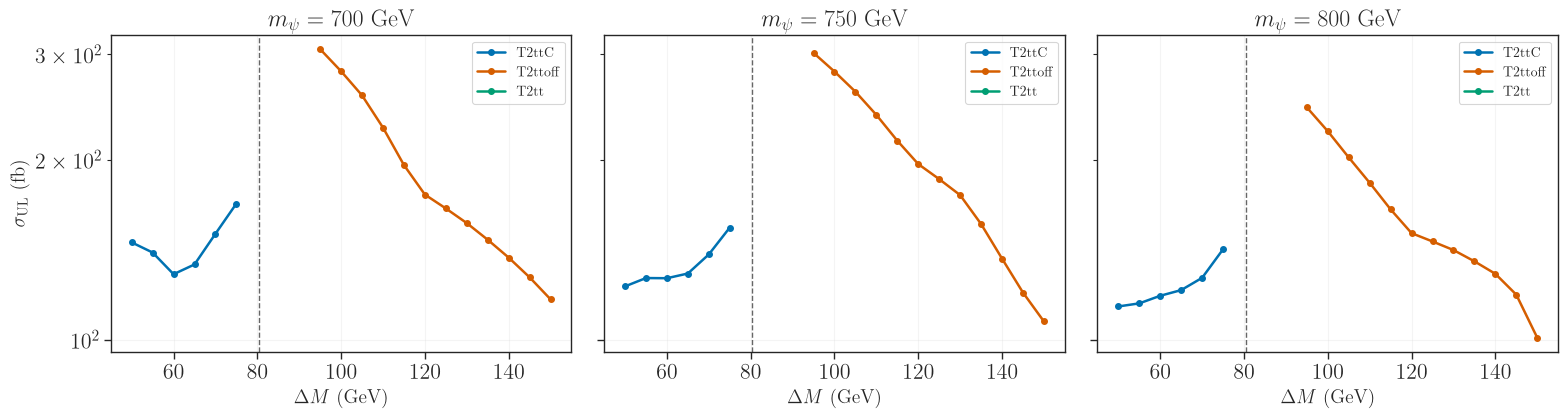

In [11]:

from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV, fb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db = Database('official')
exps = db.getExpResults(analysisIDs=['CMS-SUS-19-010'])

tx_maps = {
    name: next(
        (tx for exp in exps for tx in exp.getTxNames()
         if tx.txName == name and tx.dataType == 'upperLimit'),
        None
    )
    for name in ['T2ttC', 'T2ttoff', 'T2tt']
}

def get_ul_value(tx, mpsi, dm):
    if tx is None or mpsi <= dm:
        return np.nan

    mphi = mpsi - dm
    masses = [
        [float(mpsi)*GeV, float(mphi)*GeV],
        [float(mpsi)*GeV, float(mphi)*GeV]
    ]

    point = tx.transformPoint(masses)
    ul = tx.getULFor(sms=None, mass=point)

    return np.nan if ul is None else float(ul.asNumber(fb))

# Compare map coverage and upper limits at fixed masses
MASS_VALUES = [700, 750, 800]
DM_VALUES = np.arange(50, 151, 5)

records = []

for mpsi in MASS_VALUES:
    for dm in DM_VALUES:
        row = {'mpsi': mpsi, 'deltaM': dm}

        for name, tx in tx_maps.items():
            row[name] = get_ul_value(tx, mpsi, dm)

        records.append(row)

ul_comparison = pd.DataFrame(records)

display(ul_comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

colors = {
    'T2ttC': '#0072B2',
    'T2ttoff': '#D55E00',
    'T2tt': '#009E73'
}

for ax, mass in zip(axes, MASS_VALUES):
    subset = ul_comparison[ul_comparison.mpsi == mass]

    for name, color in colors.items():
        ax.plot(
            subset.deltaM, subset[name],
            'o-', color=color, lw=1.8, ms=4,
            label=name
        )

    ax.axvline(80.4, color='0.4', ls='--', lw=1)
    ax.set_title(rf'$m_\psi={mass}$ GeV')
    ax.set_xlabel(r'$\Delta M$ (GeV)', fontsize=14)
    ax.set_yscale('log')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.2)

axes[0].set_ylabel(r'$\sigma_{\rm UL}$ (fb)', fontsize=14)
fig.tight_layout()
plt.show()


Analysis: CMS-SUS-19-010
Total points: 729
Valid r > 0: 414
r = 0: 0
No stored r: 315
Excluded (r > 1): 194


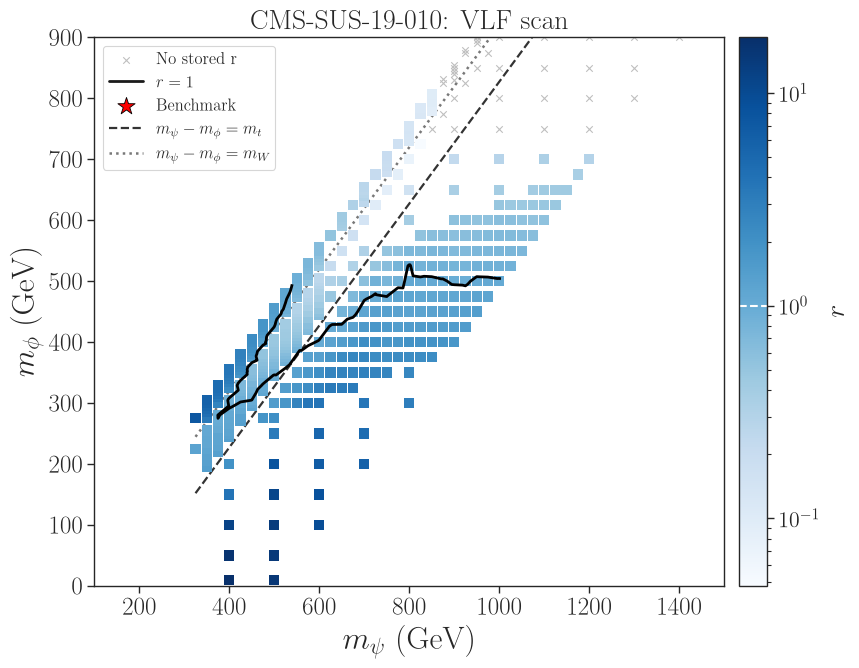

In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

# ============================================================
# Configuration
# ============================================================

ANALYSIS_ID = 'CMS-SUS-19-010'  # Change the analysis here
MPSI_COL = 'mass.5000002'
MPHI_COL = 'mass.5000012'

SHOW_R1_CONTOUR = True
SHOW_BENCHMARK_POINT = True
MAX_DX = 150   # Maximum mass separation for contour interpolation
MAX_DDM = 60   # Maximum deltaM separation for contour interpolation

# ============================================================
# 1. Extract r for the selected analysis
# ============================================================

id_cols = [
    col for col in dataDF.columns
    if col.startswith('ExptRes.result') and col.endswith('.AnalysisID')
]

matched = []

for id_col in id_cols:
    r_col = id_col.rsplit('.', 1)[0] + '.r'
    if r_col not in dataDF.columns:
        continue

    mask = dataDF[id_col].astype('string').str.strip().eq(
        ANALYSIS_ID
    ).fillna(False)

    r_values = pd.to_numeric(dataDF[r_col], errors='coerce')
    matched.append(r_values.where(mask))

if not matched:
    raise ValueError('No matching AnalysisID/r column pairs found.')

r_analysis = pd.concat(matched, axis=1).max(axis=1)

# Build dataframe
plotDF = dataDF[[MPSI_COL, MPHI_COL]].copy()
plotDF['r'] = r_analysis

plotDF.columns = ['mpsi', 'mphi', 'r']
plotDF = plotDF.apply(pd.to_numeric, errors='coerce')
plotDF = plotDF.dropna(subset=['mpsi', 'mphi'])

# Remove duplicate mass pairs
plotDF = (
    plotDF.groupby(['mpsi', 'mphi'], as_index=False)['r']
    .max()
)

plotDF['deltaM'] = plotDF.mpsi - plotDF.mphi

valid = np.isfinite(plotDF.r) & (plotDF.r > 0)
zero = np.isfinite(plotDF.r) & (plotDF.r == 0)
missing = ~np.isfinite(plotDF.r)

print(f'Analysis: {ANALYSIS_ID}')
print(f'Total points: {len(plotDF)}')
print(f'Valid r > 0: {valid.sum()}')
print(f'r = 0: {zero.sum()}')
print(f'No stored r: {missing.sum()}')
print(f'Excluded (r > 1): {(plotDF.r > 1).sum()}')

# ============================================================
# 2. Plot
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

if missing.any():
    ax.scatter(
        plotDF.loc[missing, 'mpsi'],
        plotDF.loc[missing, 'mphi'],
        marker='x', s=22, c='0.75',
        linewidths=0.8, label='No stored r',
        zorder=1
    )

if zero.any():
    ax.scatter(
        plotDF.loc[zero, 'mpsi'],
        plotDF.loc[zero, 'mphi'],
        marker='s', s=30, c='0.5',
        label=r'$r=0$', zorder=2
    )

if valid.any():
    positive = plotDF.loc[valid]

    r_min = min(float(positive.r.min()), 1.0)
    r_max = max(float(positive.r.max()), 1.0)

    if r_min == r_max:
        r_min /= 2
        r_max *= 2

    image = ax.scatter(
        positive.mpsi, positive.mphi,
        c=positive.r,
        cmap='Blues',
        norm=LogNorm(vmin=r_min, vmax=r_max),
        marker='s', s=55,
        edgecolors='none',
        rasterized=True,
        zorder=3
    )

    cb = fig.colorbar(image, ax=ax, pad=0.02)
    cb.set_label(r'$r$', fontsize=20)
    cb.ax.axhline(1, color='white', ls='--', lw=1.5)

# ============================================================
# 3. Interpolated r = 1 contour (optional)
# ============================================================

if SHOW_R1_CONTOUR and len(plotDF) >= 3 and valid.sum() >= 3:
    x = plotDF.mpsi.to_numpy(float)
    y = plotDF.mphi.to_numpy(float)
    dm = plotDF.deltaM.to_numpy(float)
    r = plotDF.r.to_numpy(float)

    triang = mtri.Triangulation(x, y)
    t = triang.triangles

    bad_vertices = (~(np.isfinite(r) & (r > 0)))[t].any(axis=1)
    bad_geometry = (
        (np.ptp(x[t], axis=1) > MAX_DX) |
        (np.ptp(dm[t], axis=1) > MAX_DDM)
    )

    triang.set_mask(bad_vertices | bad_geometry)
    good = triang.get_masked_triangles()

    if len(good):
        rv = r[good]
        crosses = (rv.min(axis=1) <= 1) & (rv.max(axis=1) >= 1)

        if crosses.any():
            logr = np.zeros_like(r)
            good_r = np.isfinite(r) & (r > 0)
            logr[good_r] = np.log10(r[good_r])

            ax.tricontour(
                triang, logr, levels=[0],
                colors='black', linewidths=2,
                zorder=4
            )

            ax.plot([], [], 'k-', lw=2, label=r'$r=1$')
        else:
            print('No supported r=1 crossing found.')

# ============================================================
# 4. Benchmark
# ============================================================

if SHOW_BENCHMARK_POINT and 'BENCHMARK' in globals():
    # BENCHMARK = (mpsi, deltaM) in the original notebook
    bm_mpsi, bm_dm = BENCHMARK
    bm_mphi = bm_mpsi - bm_dm

    ax.scatter(
        bm_mpsi, bm_mphi,
        marker='*', c='red', s=170,
        edgecolors='black', linewidths=0.6,
        label='Benchmark', zorder=6
    )

# ============================================================
# Kinematic thresholds
# ============================================================

MT = 173.0
MW = 80.4

mpsi_line = np.linspace(*ax.get_xlim(), 500)

ax.plot(mpsi_line, mpsi_line - MT,
        color='black', ls='--', lw=1.6, alpha=0.8,
        label=r'$m_\psi - m_\phi = m_t$', zorder=2)

ax.plot(mpsi_line, mpsi_line - MW,
        color='dimgray', ls=':', lw=1.8, alpha=0.9,
        label=r'$m_\psi - m_\phi = m_W$', zorder=2)

# ============================================================
# 5. Style
# ============================================================

ax.set_xlim([100, 1500])
ax.set_ylim([0,900])

ax.set_xlabel(r'$m_{\psi}$ (GeV)', fontsize=23)
ax.set_ylabel(r'$m_{\phi}$ (GeV)', fontsize=23)
ax.set_title(f'{ANALYSIS_ID}: VLF scan', fontsize=20)

ax.tick_params(axis='both', labelsize=18)
ax.legend(loc='best', fontsize=12)

fig.tight_layout()
plt.show()


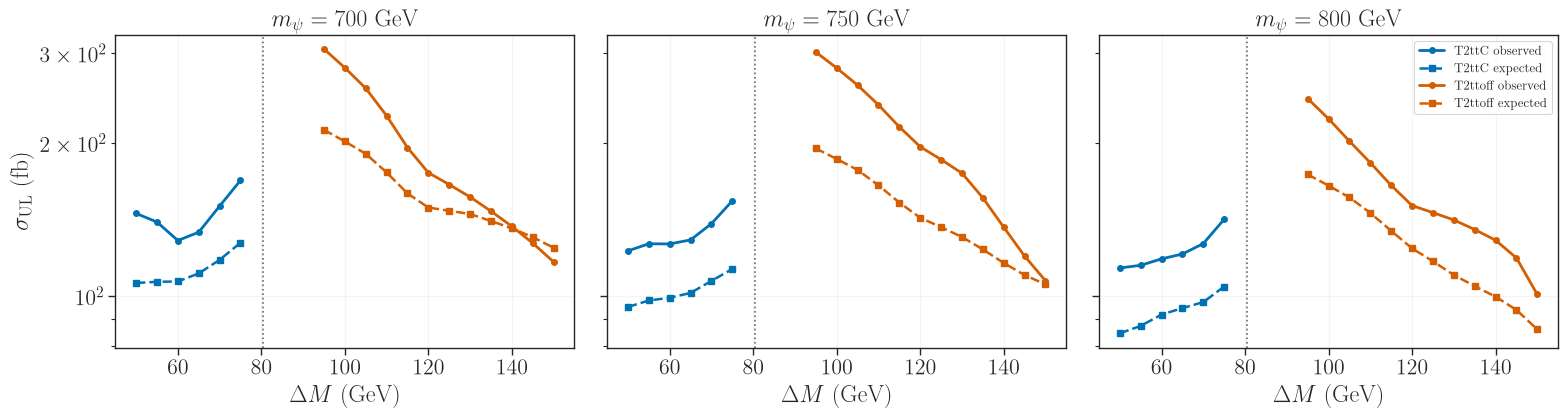

Comparison across the topology transition:

mpsi = 700 GeV
observed: UL(95)/UL(75) = 1.812
expected: UL(95)/UL(75) = 1.666

mpsi = 750 GeV
observed: UL(95)/UL(75) = 1.960
expected: UL(95)/UL(75) = 1.725

mpsi = 800 GeV
observed: UL(95)/UL(75) = 1.727
expected: UL(95)/UL(75) = 1.661


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inspect

from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV, fb

db = Database('official')
exps = db.getExpResults(analysisIDs=['CMS-SUS-19-010'])

names = ['T2ttC', 'T2ttoff']
tx_maps = {
    name: next(
        (tx for exp in exps for tx in exp.getTxNames()
         if tx.txName == name and tx.dataType == 'upperLimit'),
        None
    )
    for name in names
}

# Handle the expected-limit API in different SModelS versions
def get_ul(tx, mass, dm, expected=False):
    if tx is None:
        return np.nan

    mchi = mass - dm
    masses = [
        [mass*GeV, mchi*GeV],
        [mass*GeV, mchi*GeV]
    ]

    point = tx.transformPoint(masses)
    kwargs = {'sms': None, 'mass': point}
    params = inspect.signature(tx.getULFor).parameters

    if 'evaluationType' in params:
        from smodels.statistics.basicStats import NllEvalType
        kwargs['evaluationType'] = (
            NllEvalType.apriori if expected
            else NllEvalType.observed
        )
    elif 'expected' in params:
        kwargs['expected'] = expected
    else:
        raise RuntimeError('Unsupported SModelS getULFor API')

    ul = tx.getULFor(**kwargs)
    return np.nan if ul is None else float(ul.asNumber(fb))


MASSES = [700, 750, 800]
DELTAS = np.arange(50, 151, 5)

rows = []
for mass in MASSES:
    for dm in DELTAS:
        for name, tx in tx_maps.items():
            rows.append({
                'mpsi': mass,
                'deltaM': dm,
                'topology': name,
                'observed': get_ul(tx, mass, dm, False),
                'expected': get_ul(tx, mass, dm, True)
            })

limits = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

colors = {'T2ttC': '#0072B2', 'T2ttoff': '#D55E00'}

for ax, mass in zip(axes, MASSES):
    subset = limits[limits.mpsi == mass]

    for name, color in colors.items():
        g = subset[subset.topology == name]

        ax.plot(g.deltaM, g.observed, 'o-',
                color=color, lw=2, ms=4,
                label=f'{name} observed')

        ax.plot(g.deltaM, g.expected, 's--',
                color=color, lw=1.8, ms=4,
                label=f'{name} expected')

    ax.axvline(80.4, ls=':', color='0.4')
    ax.set_title(rf'$m_\psi={mass}$ GeV')
    ax.set_xlabel(r'$\Delta M$ (GeV)')
    ax.set_yscale('log')
    ax.grid(alpha=0.2)

axes[0].set_ylabel(r'$\sigma_{\rm UL}$ (fb)')
axes[-1].legend(fontsize=9)
fig.tight_layout()
plt.show()

# Quantify the change between the two regions
print('Comparison across the topology transition:')

for mass in MASSES:
    print(f'\nmpsi = {mass} GeV')
    for column in ['observed', 'expected']:
        a = limits[
            (limits.mpsi == mass) &
            (limits.deltaM == 75) &
            (limits.topology == 'T2ttC')
        ][column].iloc[0]

        b = limits[
            (limits.mpsi == mass) &
            (limits.deltaM == 95) &
            (limits.topology == 'T2ttoff')
        ][column].iloc[0]

        ratio = b/a if np.isfinite(a) and np.isfinite(b) else np.nan
        print(f'{column}: UL(95)/UL(75) = {ratio:.3f}')
